# 🦌 Exploración del Dataset Doñana 2024 — Observaciones con Cámaras Trampa

Este notebook analiza el archivo `observations.csv` del paquete de datos **dona_24**, que contiene registros de fauna silvestre capturados por cámaras trampa en el Parque Nacional de Doñana.

**Contenido:**
1. Carga y vista general del dataset
2. Distribución de especies (nombre científico → nombre común en español)
3. Análisis de conteos (count)
4. Análisis de confianza (classificationProbability)
5. Distribución temporal de las observaciones
6. Tipos de observación y métodos de clasificación
7. Análisis por cámara/despliegue

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path
import sys

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 100
})

In [14]:
RUNNING_IN_COLAB = "google.colab" in sys.modules

if RUNNING_IN_COLAB:
    WORKING_DIR = Path("/content")
    # En Drive para no perder el checkpoint de MegaDetector si se desconecta la sesión.
    OUTPUT_DIR = Path("/content/drive/MyDrive/donana/processed")
else:
    WORKING_DIR = Path.cwd()
    OUTPUT_DIR = WORKING_DIR / "dona_24" / "processed"

DATASET_DIR = WORKING_DIR / "dona_24"
CAMTRAP_PACKAGE_DIR = DATASET_DIR / "dona_24_pkg"
HUGGINGFACE_DATASET_ID = "wildintelproject/dona_24"

def keep_images_on_disk(media):
    return media[media["filePath"].map(lambda path: (DATASET_DIR / path).exists())]

def load_camtrap_table(table_name):
    return pd.read_csv(CAMTRAP_PACKAGE_DIR / f"{table_name}.csv")

observations = load_camtrap_table("observations")
media = load_camtrap_table("media")
media_on_disk = keep_images_on_disk(media)

In [15]:
# Solo imagenes en disco y con anotaciones
df = observations.merge(media_on_disk, on="mediaID", how="inner")
print(f'Filas: {len(df):,}  |  Columnas: {len(df.columns)}')
df.head(3)

Filas: 9,806  |  Columnas: 38


,observationID,deploymentID_x,mediaID,eventID,eventStart,eventEnd,observationLevel,observationType,cameraSetupType,scientificName,...,deploymentID_y,captureMethod,timestamp,filePath,filePublic,fileName,fileMediatype,exifData,favorite,mediaComments
0,1,r0001-dona_0006,b515fccb-aa17-5aea-982e-c61ad37060c5,d1cb76e0-1983-483b-94b4-93d4ad5ab4e5,2020-10-24T13:10:59+0000,2020-10-24T13:10:59+0000,media,animal,NaN,Dama dama,...,r0001-dona_0006,activityDetection,2020-10-24T13:10:59+0000,images/59/R0001-DONA_0006__20201024_421.JPEG,True,R0001-DONA_0006__20201024_421.JPEG,image/jpeg,NaN,False,NaN
1,5,r0001-dona_0006,6bd10347-3107-515a-b59b-9bdb29df4c43,f6744048-ca17-4e95-bdf9-9fbd76482b0d,2020-10-25T13:55:08+0000,2020-10-25T13:55:08+0000,media,animal,NaN,Sus scrofa,...,r0001-dona_0006,activityDetection,2020-10-25T13:55:08+0000,images/11/R0001-DONA_0006__20201025_642.JPEG,True,R0001-DONA_0006__20201025_642.JPEG,image/jpeg,NaN,False,NaN
2,6,r0001-dona_0006,8075b127-df52-5126-85b2-bc61ea6e3db3,f6744048-ca17-4e95-bdf9-9fbd76482b0d,2020-10-25T13:55:08+0000,2020-10-25T13:55:08+0000,media,animal,NaN,Sus scrofa,...,r0001-dona_0006,activityDetection,2020-10-25T13:55:08+0000,images/17/R0001-DONA_0006__20201025_643.JPEG,True,R0001-DONA_0006__20201025_643.JPEG,image/jpeg,NaN,False,NaN


## 1. Vista general del dataset

In [16]:
print('--- Tipos de dato ---')
print(df.dtypes.to_string())
print()
print('--- Valores nulos por columna ---')
null_pct = (df.isnull().sum() / len(df) * 100).round(1)
print(null_pct[null_pct > 0].sort_values(ascending=False).to_string())

--- Tipos de dato ---
observationID                  int64
deploymentID_x                   str
mediaID                          str
eventID                          str
eventStart                       str
eventEnd                         str
observationLevel                 str
observationType                  str
cameraSetupType              float64
scientificName                   str
count                          int64
lifeStage                    float64
sex                          float64
behavior                     float64
individualID                 float64
individualPositionRadius     float64
individualPositionAngle      float64
individualSpeed              float64
bboxX                        float64
bboxY                        float64
bboxWidth                    float64
bboxHeight                   float64
classificationMethod             str
classifiedBy                     str
classificationTimestamp          str
classificationProbability    float64
observationTags 

## 2. Distribución de especies — Nombres comunes en español

Mapeamos cada nombre científico a su nombre común en español.

In [18]:
# Diccionario nombre científico → nombre común en español
NOMBRE_COMUN = {
    'Cervus elaphus':          'Ciervo rojo',
    'Cervidae':                'Cérvido (sin especificar)',
    'Dama dama':               'Gamo',
    'Sus scrofa':              'Jabalí',
    'Bos taurus':              'Vaca / Toro',
    'Vulpes vulpes':           'Zorro rojo',
    'Leporidae':               'Lepórido (liebre/conejo)',
    'Oryctolagus cuniculus':   'Conejo europeo',
    'Meles meles':             'Tejón europeo',
    'Equus caballus':          'Caballo',
    'Lepus granatensis':       'Liebre ibérica',
    'Homo sapiens':            'Humano',
    'Herpestes ichneumon':     'Meloncillo',
    'Genetta genetta':         'Gineta',
    'Lynx pardinus':           'Lince ibérico',
}

df['nombre_comun'] = df['scientificName'].map(NOMBRE_COMUN).fillna('Desconocido')

# Tabla resumen
species_counts = (
    df[df['scientificName'].notna()]
    .groupby(['scientificName', 'nombre_comun'])
    .size()
    .reset_index(name='n_registros')
    .sort_values('n_registros', ascending=False)
    .reset_index(drop=True)
)
species_counts['porcentaje'] = (species_counts['n_registros'] / species_counts['n_registros'].sum() * 100).round(1)
species_counts

,scientificName,nombre_comun,n_registros,porcentaje
0,Cervidae,Cérvido (sin especificar),2046,26.7
1,Cervus elaphus,Ciervo rojo,1917,25.0
2,Sus scrofa,Jabalí,1672,21.8
3,Bos taurus,Vaca / Toro,1001,13.1
4,Dama dama,Gamo,392,5.1
5,Leporidae,Lepórido (liebre/conejo),220,2.9
6,Vulpes vulpes,Zorro rojo,196,2.6
7,Oryctolagus cuniculus,Conejo europeo,64,0.8
8,Meles meles,Tejón europeo,62,0.8
9,Equus caballus,Caballo,37,0.5


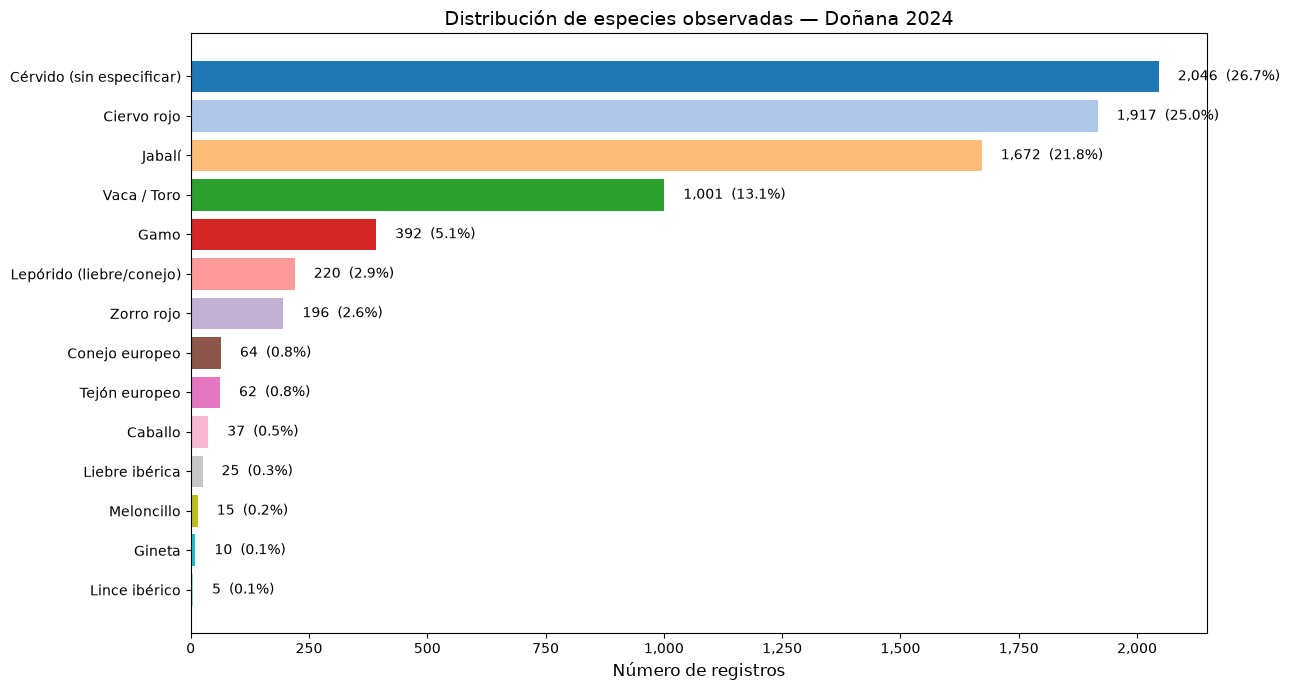

In [19]:
# Gráfico de barras — distribución de especies
fig, ax = plt.subplots(figsize=(13, 7))
colors = plt.cm.tab20(np.linspace(0, 1, len(species_counts)))

bars = ax.barh(
    species_counts['nombre_comun'],
    species_counts['n_registros'],
    color=colors
)

# Etiquetas con conteo y porcentaje
for bar, n, pct in zip(bars, species_counts['n_registros'], species_counts['porcentaje']):
    ax.text(bar.get_width() + 40, bar.get_y() + bar.get_height()/2,
            f'{n:,}  ({pct}%)', va='center', fontsize=10)

ax.set_xlabel('Número de registros')
ax.set_title('Distribución de especies observadas — Doñana 2024')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

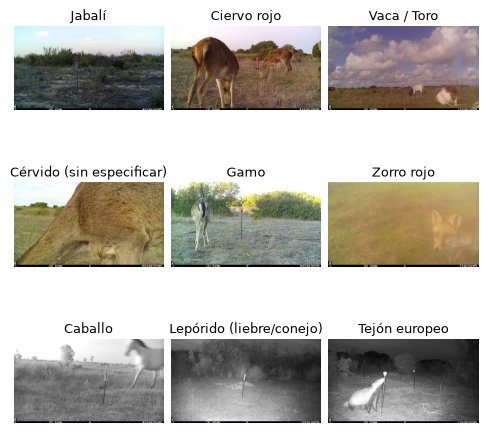

In [86]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

hora_del_dia = pd.to_datetime(df['eventStart'], errors='coerce', utc=True).dt.hour

# 1. Filtrar por probabilidad
df_valid = df[(df['nombre_comun'] != 'Desconocido') & (df['classificationProbability'] > 0.9) & ((hora_del_dia >12 ) & (hora_del_dia < 18))]

# 2. Obtener 1 muestra aleatoria por clase de forma vectorizada
muestras_por_clase = (
    df_valid.sample(frac=1, random_state=1)
    .drop_duplicates(subset=['nombre_comun'])
    .reset_index(drop=True)
).iloc[:9]

rows, cols = 3, 3
batch_size = rows * cols
total_muestras = len(muestras_por_clase)

# 3. Itera
for batch_start in range(0, total_muestras, batch_size):
    batch = muestras_por_clase.iloc[batch_start : batch_start + batch_size]
    
    # figsize=(ancho, alto): ancho para 8 columnas, alto para 2 filas
    fig, axes = plt.subplots(
        rows, cols, 
        figsize=(6, 6), 
        gridspec_kw={'hspace': 0.05, 'wspace': 0.05}  # Control preciso del espacio entre filas y columnas
    )
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        ax.axis('off')
        
        if i < len(batch):
            r = batch.iloc[i]
            img_path = str(r["filePath"])
            nombre_clase = str(r["nombre_comun"])
            
            try:
                full_path = Path(DATASET_DIR, img_path)
                img = Image.open(full_path).convert("RGB")
                ax.imshow(img)
                # pad=4 acerca el título a la imagen
                ax.set_title(nombre_clase, fontsize=9, wrap=True, pad=4)
            except Exception:
                ax.text(
                    0.5, 0.5,
                    f'{nombre_clase}\n[Error de carga]',
                    ha='center', va='center', fontsize=8
                )

    plt.show()

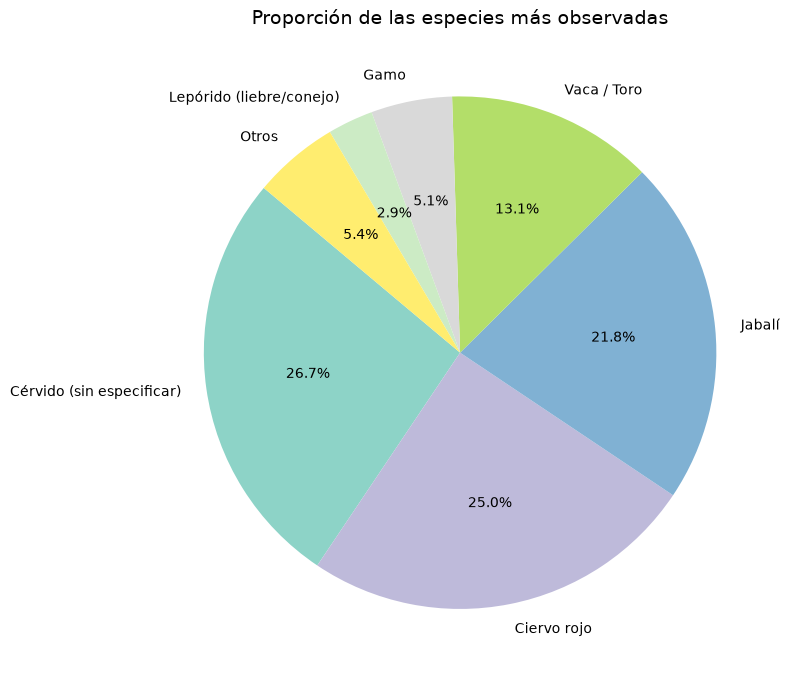

In [21]:
# Gráfico de tarta — Top 6 + Otros
top_n = 6
top = species_counts.head(top_n).copy()
otros = pd.DataFrame([{
    'nombre_comun': 'Otros',
    'n_registros': species_counts.iloc[top_n:]['n_registros'].sum()
}])
pie_data = pd.concat([top, otros], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    pie_data['n_registros'],
    labels=pie_data['nombre_comun'],
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Set3(np.linspace(0, 1, len(pie_data)))
)
ax.set_title('Proporción de las especies más observadas')
plt.tight_layout()
plt.show()

## 3. Análisis de conteos (`count`)

In [22]:
df['count'] = pd.to_numeric(df['count'], errors='coerce')

print('--- Estadísticas del campo count ---')
print(df['count'].describe().to_string())
print(f"\nRegistros con count > 1: {(df['count'] > 1).sum()}")
print(f"Conteo máximo: {df['count'].max()}")

--- Estadísticas del campo count ---
count    9806.000000
mean        1.358250
std         0.795607
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         7.000000

Registros con count > 1: 2179
Conteo máximo: 7


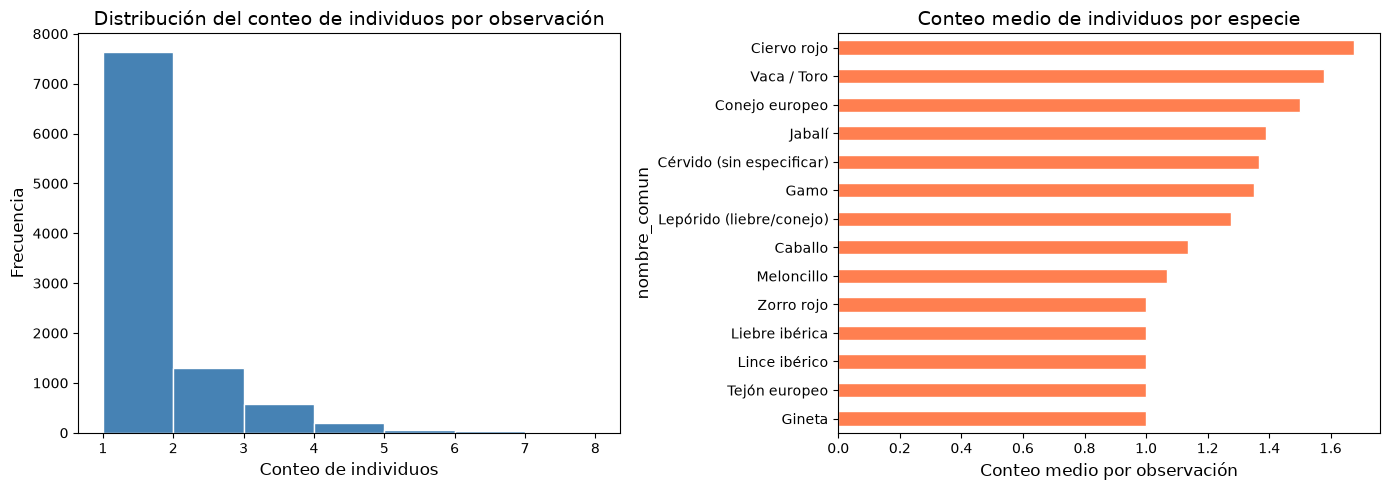

In [24]:
# Histograma del conteo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts_valid = df['count'].dropna()
axes[0].hist(counts_valid, bins=range(1, int(counts_valid.max())+2), color='steelblue', edgecolor='white')
axes[0].set_xlabel('Conteo de individuos')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribución del conteo de individuos por observación')

# Conteo medio por especie
mean_count = (
    df[df['scientificName'].notna()]
    .groupby('nombre_comun')['count']
    .mean()
    .sort_values(ascending=True)
)
mean_count.plot.barh(ax=axes[1], color='coral', edgecolor='white')
axes[1].set_xlabel('Conteo medio por observación')
axes[1].set_title('Conteo medio de individuos por especie')

plt.tight_layout()
plt.show()

## 4. Análisis de confianza (`classificationProbability`)

In [25]:
df['classificationProbability'] = pd.to_numeric(df['classificationProbability'], errors='coerce')

prob = df['classificationProbability'].dropna()
print('--- Estadísticas de classificationProbability ---')
print(prob.describe().to_string())
print(f"\nRegistros con probabilidad: {len(prob):,}")
print(f"Registros sin probabilidad: {df['classificationProbability'].isna().sum():,}")

--- Estadísticas de classificationProbability ---
count    9806.000000
mean        0.780742
std         0.170078
min         0.330000
25%         0.630000
50%         0.830000
75%         1.000000
max         1.000000

Registros con probabilidad: 9,806
Registros sin probabilidad: 0


/var/folders/d9/w858q_3s5xj1lvw2flnmb_jr0000gn/T/ipykernel_60805/2215386309.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[1].boxplot(data_for_box, vert=False, patch_artist=True,


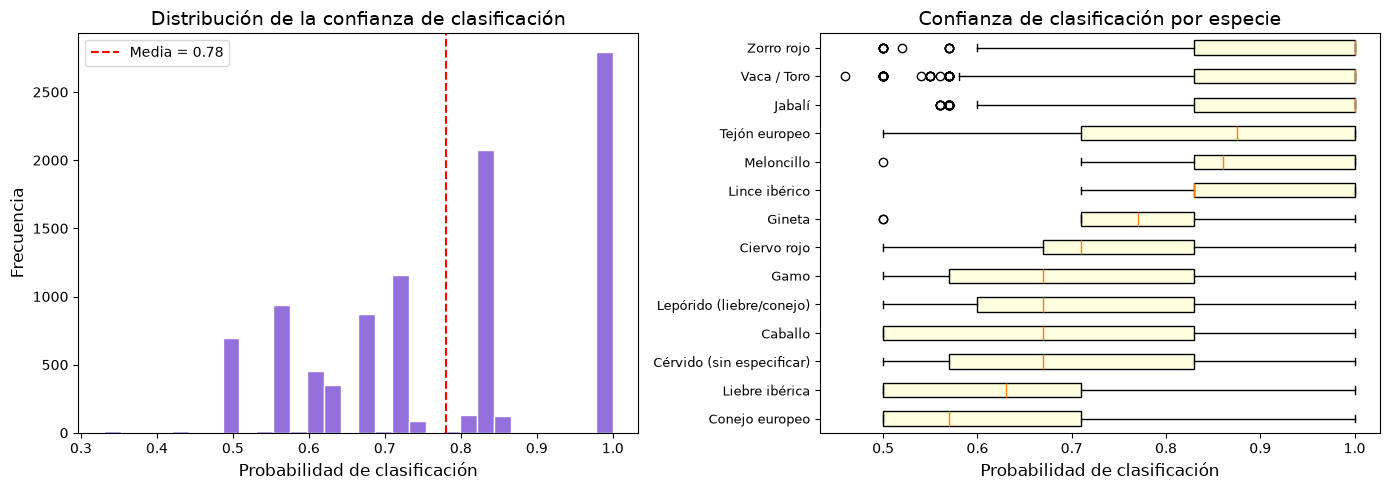

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de probabilidad
axes[0].hist(prob, bins=30, color='mediumpurple', edgecolor='white')
axes[0].set_xlabel('Probabilidad de clasificación')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribución de la confianza de clasificación')
axes[0].axvline(prob.mean(), color='red', linestyle='--', label=f'Media = {prob.mean():.2f}')
axes[0].legend()

# Boxplot de probabilidad por especie
species_with_prob = df[df['classificationProbability'].notna() & df['scientificName'].notna()]
order = species_with_prob.groupby('nombre_comun')['classificationProbability'].median().sort_values().index

data_for_box = [species_with_prob[species_with_prob['nombre_comun'] == sp]['classificationProbability'].values for sp in order]
bp = axes[1].boxplot(data_for_box, vert=False, patch_artist=True,
                     boxprops=dict(facecolor='lightyellow'))
axes[1].set_yticklabels(order, fontsize=9)
axes[1].set_xlabel('Probabilidad de clasificación')
axes[1].set_title('Confianza de clasificación por especie')

plt.tight_layout()
plt.show()

## 5. Distribución temporal de las observaciones

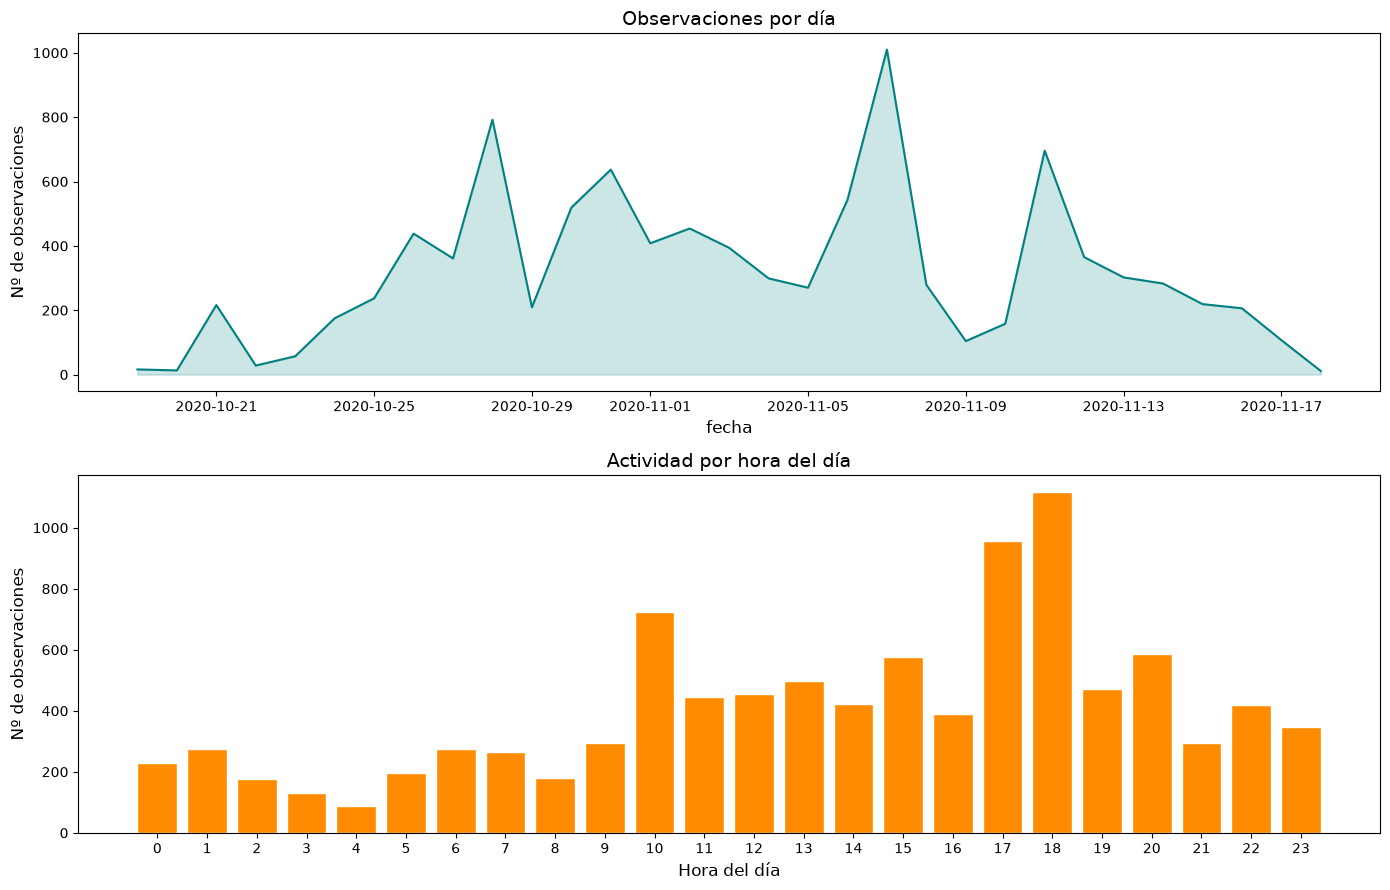

In [27]:
df['eventStart'] = pd.to_datetime(df['eventStart'], errors='coerce', utc=True)
df['fecha'] = df['eventStart'].dt.date
df['hora'] = df['eventStart'].dt.hour

# Observaciones por día
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

daily = df.groupby('fecha').size()
daily.plot(ax=axes[0], color='teal', linewidth=1.5)
axes[0].set_ylabel('Nº de observaciones')
axes[0].set_title('Observaciones por día')
axes[0].fill_between(daily.index, daily.values, alpha=0.2, color='teal')

# Observaciones por hora del día
hourly = df.groupby('hora').size()
axes[1].bar(hourly.index, hourly.values, color='darkorange', edgecolor='white')
axes[1].set_xlabel('Hora del día')
axes[1].set_ylabel('Nº de observaciones')
axes[1].set_title('Actividad por hora del día')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

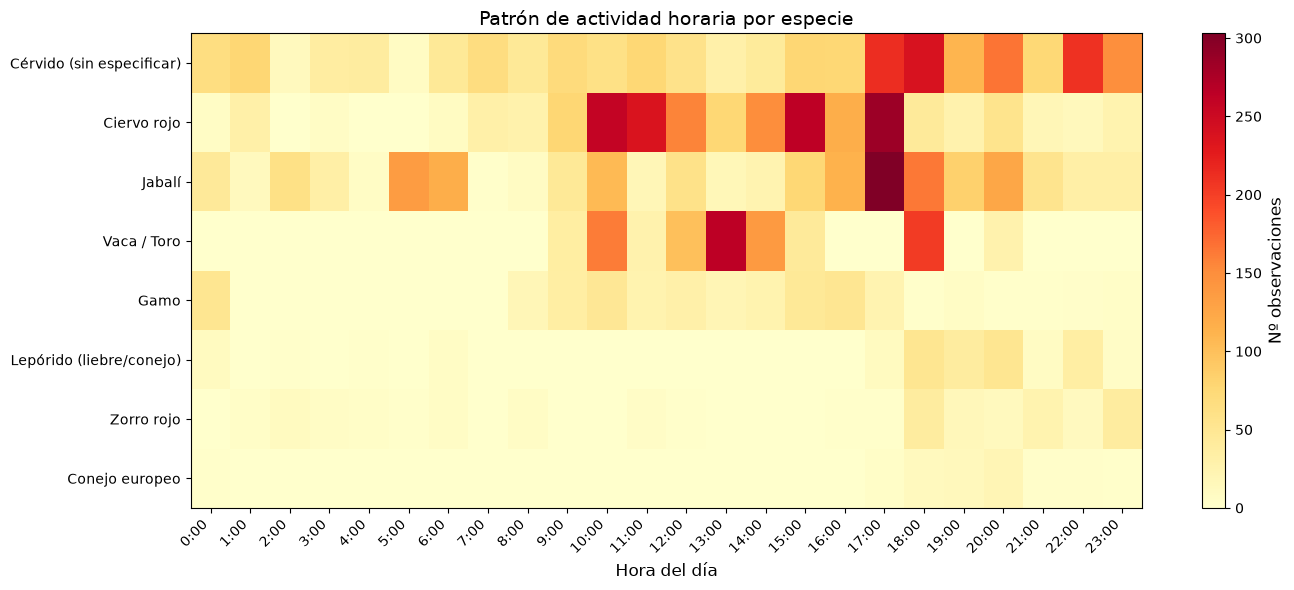

In [28]:
# Heatmap: actividad horaria por especie (top 8)
top_species = species_counts.head(8)['nombre_comun'].tolist()
subset = df[df['nombre_comun'].isin(top_species)].copy()

pivot = subset.groupby(['nombre_comun', 'hora']).size().unstack(fill_value=0)
pivot = pivot.reindex(top_species)  # mantener orden de abundancia

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xticks(range(24))
ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45, ha='right')
ax.set_xlabel('Hora del día')
ax.set_title('Patrón de actividad horaria por especie')
plt.colorbar(im, ax=ax, label='Nº observaciones')
plt.tight_layout()
plt.show()

## 6. Análisis por cámara / despliegue (`deploymentID`)

In [31]:
df.columns

Index(['observationID', 'deploymentID_x', 'mediaID', 'eventID', 'eventStart',
       'eventEnd', 'observationLevel', 'observationType', 'cameraSetupType',
       'scientificName', 'count', 'lifeStage', 'sex', 'behavior',
       'individualID', 'individualPositionRadius', 'individualPositionAngle',
       'individualSpeed', 'bboxX', 'bboxY', 'bboxWidth', 'bboxHeight',
       'classificationMethod', 'classifiedBy', 'classificationTimestamp',
       'classificationProbability', 'observationTags', 'observationComments',
       'deploymentID_y', 'captureMethod', 'timestamp', 'filePath',
       'filePublic', 'fileName', 'fileMediatype', 'exifData', 'favorite',
       'mediaComments', 'nombre_comun', 'fecha', 'hora'],
      dtype='str')

Número total de despliegues (cámaras): 37
Observaciones por cámara — media: 265, mediana: 80
Cámara con más registros: r0001-dona_0021 (2,920)


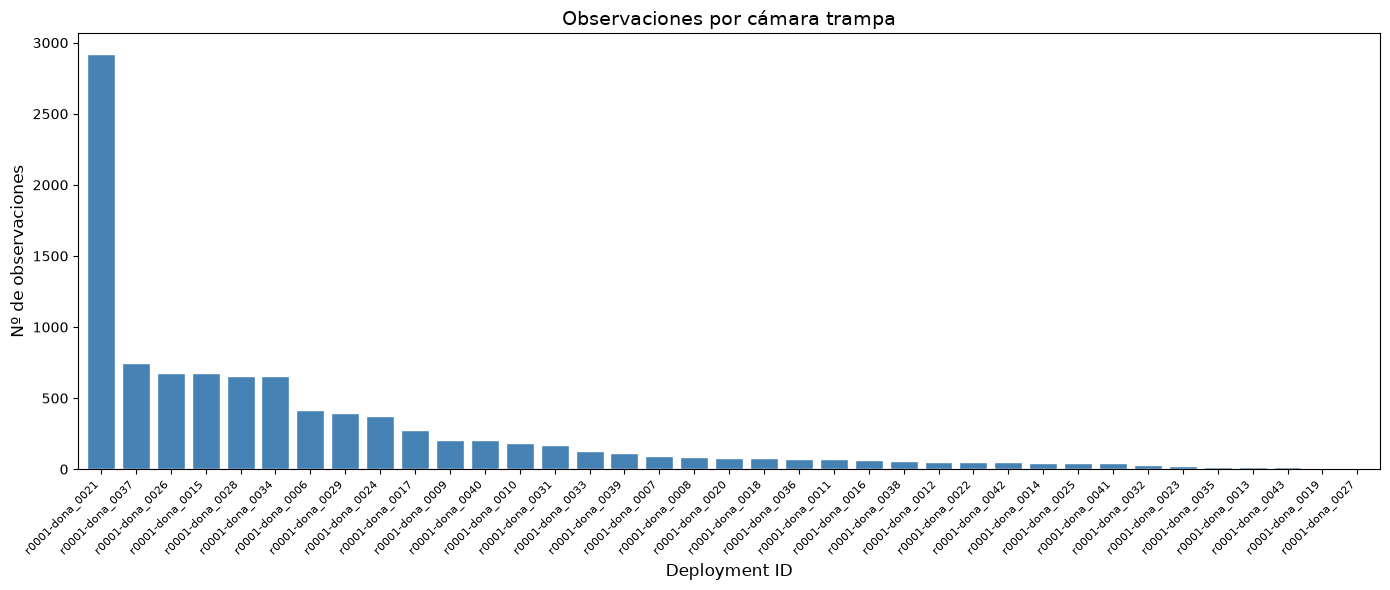

In [32]:
deploy_counts = df.groupby('deploymentID_x').size().sort_values(ascending=False)
print(f'Número total de despliegues (cámaras): {deploy_counts.shape[0]}')
print(f'Observaciones por cámara — media: {deploy_counts.mean():.0f}, mediana: {deploy_counts.median():.0f}')
print(f'Cámara con más registros: {deploy_counts.index[0]} ({deploy_counts.iloc[0]:,})')

fig, ax = plt.subplots(figsize=(14, 6))
deploy_counts.plot.bar(ax=ax, color='steelblue', edgecolor='white', width=0.8)
ax.set_ylabel('Nº de observaciones')
ax.set_xlabel('Deployment ID')
ax.set_title('Observaciones por cámara trampa')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

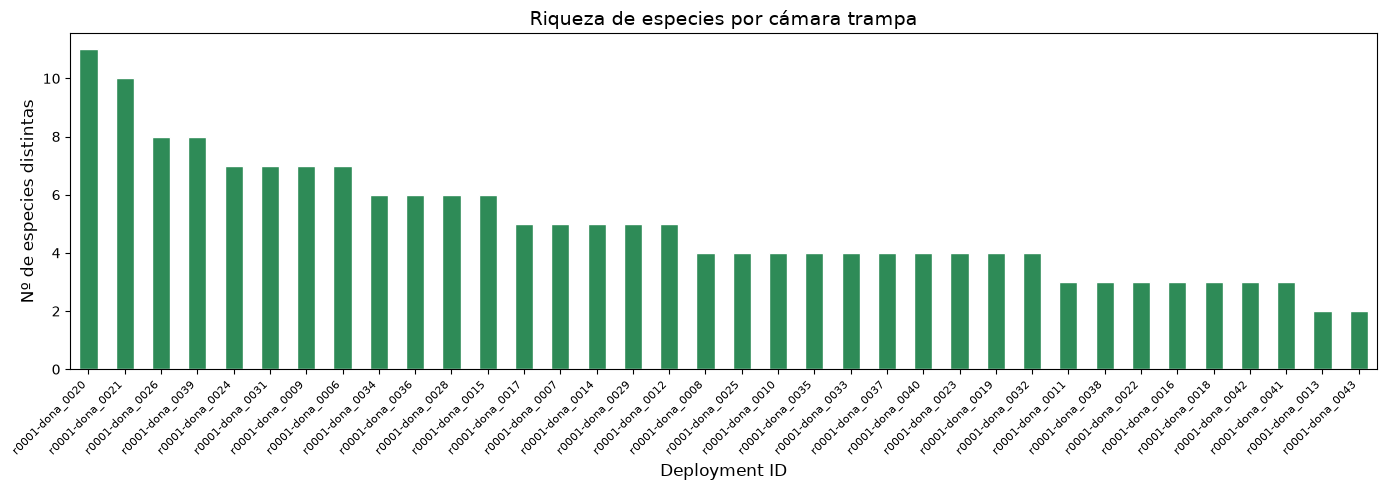

In [34]:
# Riqueza de especies por cámara
richness = (
    df[df['scientificName'].notna()]
    .groupby('deploymentID_x')['scientificName']
    .nunique()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 5))
richness.plot.bar(ax=ax, color='seagreen', edgecolor='white')
ax.set_ylabel('Nº de especies distintas')
ax.set_xlabel('Deployment ID')
ax.set_title('Riqueza de especies por cámara trampa')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

## 8. Especies destacadas 🐾

Un breve resumen de hallazgos interesantes.

In [36]:
# Resumen de especies relevantes
highlight = df[df['scientificName'].notna()].copy()

resumen = (
    highlight.groupby('nombre_comun')
    .agg(
        total_registros=('observationID', 'count'),
        conteo_medio=('count', 'mean'),
        conteo_max=('count', 'max'),
        confianza_media=('classificationProbability', 'mean'),
        confianza_min=('classificationProbability', 'min'),
        n_camaras=('deploymentID_x', 'nunique'),
    )
    .round(2)
    .sort_values('total_registros', ascending=False)
)

resumen

,total_registros,conteo_medio,conteo_max,confianza_media,confianza_min,n_camaras
nombre_comun,,,,,,
Cérvido (sin especificar),2046,1.37,6,0.68,0.50,32
Ciervo rojo,1917,1.68,6,0.74,0.50,28
Jabalí,1672,1.39,7,0.92,0.56,28
Vaca / Toro,1001,1.58,7,0.92,0.46,7
Gamo,392,1.35,6,0.70,0.50,20
Lepórido (liebre/conejo),220,1.28,4,0.70,0.50,9
Zorro rojo,196,1.00,1,0.88,0.50,21
Conejo europeo,64,1.50,3,0.62,0.50,5
Tejón europeo,62,1.00,1,0.86,0.50,9


---
## Conclusiones principales

- **Ciervo rojo** (*Cervus elaphus*) y **Cérvidos** (sin especificar) son las especies más frecuentes.
- El **jabalí** (*Sus scrofa*) es la segunda especie más registrada.
- Se registran también **ganado doméstico** (vacas y caballos), habitual en Doñana.
- El **lince ibérico** aparece en un número muy reducido de registros — dato valioso para su conservación.
- La confianza de clasificación varía significativamente entre especies — los cérvidos sin especificar suelen tener menor confianza.
- La actividad presenta un claro **patrón crepuscular/nocturno** en la mayoría de las especies.